# Procesado de datos

## Ejemplo

In [1]:
import cv2
import os
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import accuracy_score
from sklearn.model_selection import LeaveOneOut, cross_val_score
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

Variables

In [2]:
IMG_SIZE = 256

In [3]:
nodo1 = cv2.imread("./fotogramas/Fotogramas/nodo6/nodo500810.jpg")
RGB_img = cv2.cvtColor(nodo1, cv2.COLOR_BGR2RGB)

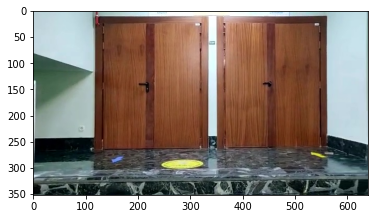

In [4]:
plt.imshow(RGB_img)
plt.show()

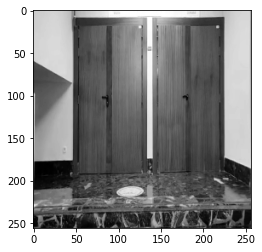

In [55]:
grayImage = cv2.cvtColor(nodo1, cv2.COLOR_BGR2GRAY)
img_pred = cv2.resize(grayImage, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
plt.imshow(img_pred, cmap='gray')
plt.show()

In [56]:
hist = cv2.calcHist([img_pred], [0], None, [256], [0, 256])
hist /= hist.sum() # Normalize

(0.0, 256.0)

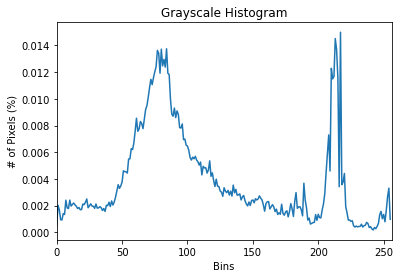

In [57]:
# plot the histogram
plt.figure()
plt.title("Grayscale Histogram")
plt.xlabel("Bins")
plt.ylabel("# of Pixels (%)")
plt.plot(hist)
plt.xlim([0, 256])

## Procesado de los fotogramas y volcado de los histogramas en CSVs

Nota: la primera fila de los csv de los histogramas de cada nodo individual son los índices de las columnas (del 0 al 255). Los datos empiezan en la segunda fila

In [8]:
i = 1
df = None
df_norm = None
first_all = True

for i in range(6):
    first = True
    node='nodo'+str(i+1)
    print(node)
    for image_file in os.listdir("./fotogramas/Fotogramas/{}".format(node)):
        image = cv2.imread("./fotogramas/Fotogramas/{}/{}".format(node,image_file))
        grayImage = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        img_pred = cv2.resize(grayImage, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        hist = cv2.calcHist([img_pred], [0], None, [256], [0, 256])
        hist_norm = hist / hist.sum() # Normalize
        if first:
            df = pd.DataFrame(hist.T, index=None)
            df_norm = pd.DataFrame(hist_norm.T, index=None)
            first = False
        else:
            df = df.append(pd.DataFrame(hist.T, index=None))
            df_norm = df_norm.append(pd.DataFrame(hist_norm.T, index=None))
        
        if first_all:

            labels = [int(node[-1])]
            res = pd.DataFrame()
            res = pd.DataFrame(hist.flatten(), index=None).transpose()

            res_norm = pd.DataFrame()
            res_norm = pd.DataFrame(hist_norm.flatten(), index=None).transpose()
            first_all = False

        else:
            labels.append(int(node[-1]))
            index = len(res)
            res.loc[index,:] = hist.flatten().reshape((1,256))
            
            res_norm.loc[index,:] = hist_norm.flatten().reshape((1,256))


    df.to_csv("./histogramas/{}.csv".format(node), index=None)
    df_norm.to_csv("./histogramas/{}_norm.csv".format(node), index=None)
    i += 1

res['nodo'] = labels
res_norm['nodo'] = labels

res.to_csv("./histogramas/ALL.csv", index=None)
res_norm.to_csv("./histogramas/ALL_norm.csv", index=None)


nodo1
nodo2
nodo3
nodo4
nodo5
nodo6


# Generación modelo

In [9]:
data = pd.read_csv("./histogramas/ALL_norm.csv")
print(data.shape)
data.head()

(2842, 257)


,0,1,2,3,4,5,6,7,8,9,...,247,248,249,250,251,252,253,254,255,nodo
0,0.000137,0.001389,0.002106,0.002655,0.002411,0.004242,0.004395,0.004517,0.005280,0.005325,...,0.000137,0.000092,0.000320,0.000351,0.000580,0.001022,0.001678,0.003006,0.001541,1
1,0.000015,0.002441,0.005478,0.004852,0.004074,0.006027,0.007248,0.008713,0.008087,0.009811,...,0.000229,0.000305,0.000168,0.000183,0.000381,0.000793,0.001205,0.002213,0.000565,1
2,0.004608,0.007538,0.006668,0.006332,0.005661,0.006027,0.006027,0.005234,0.004745,0.004333,...,0.001038,0.000961,0.001038,0.001175,0.001587,0.002060,0.003540,0.007233,0.002914,1
3,0.000000,0.000305,0.003952,0.003189,0.003555,0.006073,0.006317,0.006439,0.008163,0.007614,...,0.000351,0.000305,0.000412,0.000427,0.000793,0.000900,0.001663,0.004456,0.005280,1
4,0.005157,0.005005,0.004730,0.004028,0.003922,0.004028,0.004807,0.005096,0.004623,0.003784,...,0.001175,0.001404,0.001312,0.001633,0.002167,0.003342,0.005447,0.005325,0.001053,1


In [10]:
train_data = pd.DataFrame()
for i in range(6):
    train_data = train_data.append(data[data.nodo == i+1][:100])
print(train_data.shape)
train_data.head()

(600, 257)


,0,1,2,3,4,5,6,7,8,9,...,247,248,249,250,251,252,253,254,255,nodo
0,0.000137,0.001389,0.002106,0.002655,0.002411,0.004242,0.004395,0.004517,0.005280,0.005325,...,0.000137,0.000092,0.000320,0.000351,0.000580,0.001022,0.001678,0.003006,0.001541,1
1,0.000015,0.002441,0.005478,0.004852,0.004074,0.006027,0.007248,0.008713,0.008087,0.009811,...,0.000229,0.000305,0.000168,0.000183,0.000381,0.000793,0.001205,0.002213,0.000565,1
2,0.004608,0.007538,0.006668,0.006332,0.005661,0.006027,0.006027,0.005234,0.004745,0.004333,...,0.001038,0.000961,0.001038,0.001175,0.001587,0.002060,0.003540,0.007233,0.002914,1
3,0.000000,0.000305,0.003952,0.003189,0.003555,0.006073,0.006317,0.006439,0.008163,0.007614,...,0.000351,0.000305,0.000412,0.000427,0.000793,0.000900,0.001663,0.004456,0.005280,1
4,0.005157,0.005005,0.004730,0.004028,0.003922,0.004028,0.004807,0.005096,0.004623,0.003784,...,0.001175,0.001404,0.001312,0.001633,0.002167,0.003342,0.005447,0.005325,0.001053,1


In [11]:
x_train = train_data.iloc[:,:-1]
y_train = train_data.iloc[:,-1]

x_test = data.iloc[:, :-1]
y_test = data.iloc[:, -1]

In [12]:
def train_LOE(x, y):
    cv = LeaveOneOut()
    model = KNeighborsClassifier(n_neighbors=1)
    model_distance = NearestNeighbors(n_neighbors=1)
    scores = cross_val_score(model, x, y, cv=cv, scoring='accuracy', n_jobs=-1)
    accuracy = round(np.mean(scores)*100,2)

    return accuracy, (model.fit(x, y), model_distance.fit(x,y))

In [13]:
accuracy, models = train_LOE(x_train, y_train)


In [14]:
print(f'La precisión del modelo es de {accuracy}%')

La precisión del modelo es de 99.17%


In [15]:
#model = KNeighborsClassifier(n_neighbors=1)
#model.fit(x, y)
#
#predictions = model.predict(x_test)
#precision = accuracy_score(y_test, predictions)
#print(f'La precisión del modelo es de {round(precision*100, 2)}%')

In [16]:
def model_predict_hist(model, data, threshold = None):
    model = model[0]
    prediction = model.predict(data)[0]

    if threshold :
        model_distance = models[1]
        distance = model_distance.kneighbors(data)[0][0][0]
        print('Distance: ', distance)
        if distance > threshold:
            prediction = None

    return prediction
    

In [17]:
def dynamicLab(i):
    if(i<=500):
        return 1
    if(i>500 and i<=1250):
        return 2
    if(i>1250 and i<=1880):
        return 3
    if(i>1880 and i<=2660):
        return 4
    if(i>2660 and i<=2770):
        return 5
    else:
        return 6

In [18]:
capture = cv2.VideoCapture('./test.mp4')
key=None
fontColor= (0, 250, 250)
node=1
i=0
aciertos=0
while (key != 32):
    # Leo una imagen del video
    ret,X = capture.read()
    
    if not ret:
        print('Se acabo el video.')
        cv2.destroyAllWindows()
        break
    
    imgGray=cv2.cvtColor(X, cv2.COLOR_BGR2GRAY)
    #pdb.set_trace()
    img_pred = cv2.resize(imgGray, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    hist = cv2.calcHist([img_pred], [0], None, [256], [0, 256])
    hist_norm = hist / hist.sum() # Normalize
    hist_norm= np.reshape(hist_norm, (1, 256))
    #pred = model_predict_hist(models, hist_norm)
    pred=model_predict_hist(models, hist_norm)
    #import pdb; pdb.set_trace()
    print('pred: ', pred)
    if(pred!=None):
        node=pred
    aciertos=aciertos+(node==dynamicLab(i))
    cv2.putText(X, 'Nodo '+str(node), (10, 30), cv2.FONT_HERSHEY_PLAIN,2, fontColor, 2)
    cv2.putText(X, str(i), (10, 200), cv2.FONT_HERSHEY_PLAIN,2, fontColor, 2)
    cv2.imshow('video',X)
    key = cv2.waitKey(35)
    i+=1


    #import pdb; pdb.set_trace()
    
dynamicAccuracy=(aciertos/i)*100
print('La precision en el video es: ', dynamicAccuracy)
# Cierro la ventana 
cv2.destroyAllWindows() 
capture.release()

pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
pred:  1
p

pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
pred:  2
p

pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
pred:  4
p

pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
pred:  6
p